# Deep Neural Network (L-Layer Model)
In this notebook, we implement a Deep Neural Network (DNN) with multiple hidden layers ([LINEAR -> RELU] * (L-1) -> LINEAR -> SIGMOID) to forecast hourly day-ahead electricity prices in Spain, following the methodology we used in previous notebooks.

# 1 - Packages

In [1]:
# Package imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from pathlib import Path

# 2 - Load the Dataset and Normalization
The same data split was used for this NN:

-2023-2024: Training

-2025: Validation and test

In [2]:
# Loading the dataset
input_path = Path("model_input") / "Master_Dataset_Engineered_2023_2025.xlsx"
df = pd.read_excel(input_path)
input_data = df.values

In [6]:
train_set_x_orig = input_data[:17376, 2:].astype(float)
train_set_y_orig = input_data[:17376, 1:2].astype(float)

test_set_x_orig  = input_data[17376:, 2:].astype(float)
test_set_y_orig  = input_data[17376:, 1:2].astype(float)

print("train_set_x_orig shape:", train_set_x_orig.shape)
print("train_set_y_orig shape:", train_set_y_orig.shape)
print("test_set_x_orig shape: ", test_set_x_orig.shape)
print("test_set_y_orig shape: ", test_set_y_orig.shape)

train_set_x_orig shape: (17376, 12)
train_set_y_orig shape: (17376, 1)
test_set_x_orig shape:  (8760, 12)
test_set_y_orig shape:  (8760, 1)


In [5]:
scaler = MinMaxScaler(feature_range=(0, 1))

train_set_x_normalized = scaler.fit_transform(train_set_x_orig)
test_set_x_normalized  = scaler.fit_transform(test_set_x_orig)
train_set_y_normalized = scaler.fit_transform(train_set_y_orig)
test_set_y_normalized  = scaler.fit_transform(test_set_y_orig)

train_set_x_normalized = train_set_x_normalized.T
test_set_x_normalized  = test_set_x_normalized.T
train_set_y_normalized = train_set_y_normalized.T
test_set_y_normalized  = test_set_y_normalized.T

In [7]:
m_train = train_set_x_orig.shape[0]
m_test  = test_set_x_orig.shape[0]

print("Number of training examples: m_train = " + str(m_train))
print("Number of testing examples:  m_test  = " + str(m_test))
print("train_set_x shape: " + str(train_set_x_normalized.shape))
print("train_set_y shape: " + str(train_set_y_normalized.shape))
print("test_set_x shape:  " + str(test_set_x_normalized.shape))
print("test_set_y shape:  " + str(test_set_y_normalized.shape))

Number of training examples: m_train = 17376
Number of testing examples:  m_test  = 8760
train_set_x shape: (12, 17376)
train_set_y shape: (1, 17376)
test_set_x shape:  (12, 8760)
test_set_y shape:  (1, 8760)


# 3 - Deep Neural Network functions
Following the course tutorial labs, we build the helper functions for a Deep Neural Network:
- Hidden layers: LINEAR -> RELU
- Output layer: LINEAR -> SIGMOID

### 3.1 - Activation functions and derivatives 

In [8]:
def sigmoid(Z):
    A = 1 / (1 + np.exp(-Z))
    cache = Z
    return A, cache

def relu(Z):
    A = np.maximum(0, Z)
    cache = Z
    return A, cache

def relu_backward(dA, cache):
    Z = cache
    dZ = np.array(dA, copy=True)
    dZ[Z <= 0] = 0
    return dZ

def sigmoid_backward(dA, cache):
    Z = cache
    s = 1 / (1 + np.exp(-Z))
    dZ = dA * s * (1 - s)
    return dZ

### 3.2 - Parameter initialization 

In [9]:
def initialize_parameters_deep(layer_dims):

    np.random.seed(1)
    parameters = {}
    L = len(layer_dims)  #number of layers in the network

    for l in range(1, L):
        parameters['W' + str(l)] = np.random.randn(layer_dims[l], layer_dims[l-1]) / np.sqrt(layer_dims[l-1])
        parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))
        
    return parameters

### 3.3 - Forward propagation

In [ ]:
def linear_forward(A, W, b):
    Z = np.dot(W, A) + b
    cache = (A, W, b)
    return Z, cache

def linear_activation_forward(A_prev, W, b, activation):
    if activation == "sigmoid":
        Z, linear_cache = linear_forward(A_prev, W, b)
        A, activation_cache = sigmoid(Z)
    elif activation == "relu":
        Z, linear_cache = linear_forward(A_prev, W, b)
        A, activation_cache = relu(Z)
        
    cache = (linear_cache, activation_cache)
    return A, cache

def L_model_forward(X, parameters):
    caches = []
    A = X
    L = len(parameters) // 2  # number of layers in the neural network
    
    for l in range(1, L):
        A_prev = A
        A, cache = linear_activation_forward(A_prev, parameters['W' + str(l)], parameters['b' + str(l)], activation="relu")
        caches.append(cache)
    
    AL, cache = linear_activation_forward(A, parameters['W' + str(L)], parameters['b' + str(L)], activation="sigmoid")
    caches.append(cache)
            
    return AL, caches

### 3.4 - Cost

In [11]:
def compute_cost(AL, Y):
    m = Y.shape[1]
    cost = (-1 / m) * np.sum(Y * np.log(AL) + (1 - Y) * np.log(1 - AL))
    cost = float(np.squeeze(cost))
    return cost

### 3.5 - Backward propagation

In [13]:
def linear_backward(dZ, cache):
    A_prev, W, b = cache
    m = A_prev.shape[1]

    dW = (1 / m) * np.dot(dZ, A_prev.T)
    db = (1 / m) * np.sum(dZ, axis=1, keepdims=True)
    dA_prev = np.dot(W.T, dZ)
    
    return dA_prev, dW, db

def linear_activation_backward(dA, cache, activation):
    linear_cache, activation_cache = cache
    
    if activation == "relu":
        dZ = relu_backward(dA, activation_cache)
        dA_prev, dW, db = linear_backward(dZ, linear_cache)
    elif activation == "sigmoid":
        dZ = sigmoid_backward(dA, activation_cache)
        dA_prev, dW, db = linear_backward(dZ, linear_cache)
    
    return dA_prev, dW, db

def L_model_backward(AL, Y, caches):
    grads = {}
    L = len(caches)  # number of layers
    m = AL.shape[1]
    Y = Y.reshape(AL.shape)
    
    dAL = - (np.divide(Y, AL) - np.divide(1 - Y, 1 - AL))
    
    current_cache = caches[L-1]
    dA_prev_temp, dW_temp, db_temp = linear_activation_backward(dAL, current_cache, activation="sigmoid")
    grads["dA" + str(L-1)] = dA_prev_temp
    grads["dW" + str(L)]   = dW_temp
    grads["db" + str(L)]   = db_temp
   
    for l in reversed(range(L-1)):
        current_cache = caches[l]
        dA_prev_temp, dW_temp, db_temp = linear_activation_backward(grads["dA" + str(l + 1)], current_cache, activation="relu")
        grads["dA" + str(l)]     = dA_prev_temp
        grads["dW" + str(l + 1)] = dW_temp
        grads["db" + str(l + 1)] = db_temp

    return grads

### 3.6 - Update params

In [12]:
def update_parameters(params, grads, learning_rate):
    parameters = params.copy()
    L = len(parameters) // 2  # number of layers in the neural network

    for l in range(L):
        parameters["W" + str(l+1)] = parameters["W" + str(l+1)] - learning_rate * grads["dW" + str(l+1)]
        parameters["b" + str(l+1)] = parameters["b" + str(l+1)] - learning_rate * grads["db" + str(l+1)]
        
    return parameters

### 3.7 - Model

In [14]:
def L_layer_model(X, Y, layers_dims, learning_rate=0.5, num_iterations=2000, print_cost=False):

    np.random.seed(1)
    costs = []
    
    parameters = initialize_parameters_deep(layers_dims)
    
    for i in range(0, num_iterations):
        AL, caches = L_model_forward(X, parameters)
        cost = compute_cost(AL, Y)
        grads = L_model_backward(AL, Y, caches)
        parameters = update_parameters(parameters, grads, learning_rate)
        
        if i % 100 == 0:
            costs.append(cost)
            if print_cost:
                print("Cost after iteration {}: {:.6f}".format(i, cost))
    
    return parameters, costs

# 4 - Predict and Model Training (12 Features)
### 4.1 - Predict 

In [15]:
def predict(parameters, X):
    AL, caches = L_model_forward(X, parameters)
    predictions = AL
    return predictions

### 4.2 - Test the Baseline 4-Layer DNN on the Electricity Dataset 
Following the course tutorial, we first train a 4-layer network with 3 hidden layers: 

-layers_dims = [12, 20, 10, 5, 1]

-learning_rate = 0.5

-num_iterations = 2000

In [16]:
# 4-layer model: 12 inputs -> 20 -> 10 -> 5 -> 1 output
layers_dims = [12, 20, 10, 5, 1]
learning_rate = 0.5
num_iterations = 2000

parameters, costs = L_layer_model(
    train_set_x_normalized,
    train_set_y_normalized,
    layers_dims,
    learning_rate=learning_rate,
    num_iterations=num_iterations,
    print_cost=True
)

Y_prediction_train = predict(parameters, train_set_x_normalized)
Train_accuracy = 100 - np.mean(np.abs(Y_prediction_train - train_set_y_normalized)) * 100

Y_prediction_test = predict(parameters, test_set_x_normalized)
Test_accuracy = 100 - np.mean(np.abs(Y_prediction_test - test_set_y_normalized)) * 100

print("Train Accuracy: {} %".format(Train_accuracy))
print("Test Accuracy:  {} %".format(Test_accuracy))

Cost after iteration 0: 0.683218
Cost after iteration 100: 0.571468
Cost after iteration 200: 0.562442
Cost after iteration 300: 0.559766
Cost after iteration 400: 0.558556
Cost after iteration 500: 0.557837
Cost after iteration 600: 0.557269
Cost after iteration 700: 0.556883
Cost after iteration 800: 0.556550
Cost after iteration 900: 0.556209
Cost after iteration 1000: 0.555873
Cost after iteration 1100: 0.555677
Cost after iteration 1200: 0.555417
Cost after iteration 1300: 0.555231
Cost after iteration 1400: 0.555089
Cost after iteration 1500: 0.554852
Cost after iteration 1600: 0.554658
Cost after iteration 1700: 0.554446
Cost after iteration 1800: 0.554261
Cost after iteration 1900: 0.554185
Train Accuracy: 94.27581824431746 %
Test Accuracy:  93.62167136773533 %


### Cost Function
Plot of the cost function across training iterations.

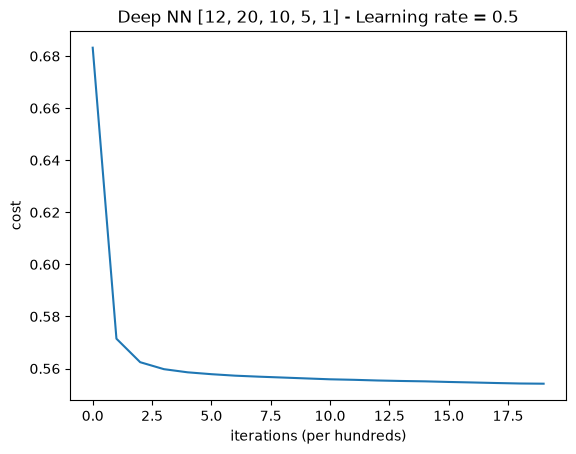

In [17]:
plt.plot(np.squeeze(costs))
plt.ylabel("cost")
plt.xlabel("iterations (per hundreds)")
plt.title("Deep NN [12, 20, 10, 5, 1] - Learning rate = " + str(learning_rate))
plt.show()

### Denormalizing
Reverse the Min-Max normalization to obtain the predicted electricity prices in EUR/MWh.

In [18]:
Y_prediction_test_real_scale = scaler.inverse_transform(predict(parameters, test_set_x_normalized))

# 5 - Hyperparameter optimization
As in Logistic Regression and the Shallow Neural Network, we use the 1st half of 2025 ([:4380]) as the Validation to tune the hidden-layer architecture, learning_rate`, and num_iterations, and keep the 2nd half of 2025 ([4380:]) as the Final Test Set.

### 5.1 - Grid search

In [22]:
# First half of 2025 for hyperparameter optimization (Validation Set)
X_val_norm = test_set_x_normalized[:, :4380]
Y_val_norm = test_set_y_normalized[:, :4380]
y_val_orig = test_set_y_orig[:4380, :]

# Second half of 2025 for final evaluation (Final Test Set)
X_test_final_norm = test_set_x_normalized[:, 4380:]
Y_test_final_norm = test_set_y_normalized[:, 4380:]
y_test_final_orig = test_set_y_orig[4380:, :]

# Candidate hidden-layer architectures (2, 3, and 4 hidden layers)
architectures = {
    "[10, 5]":          [12, 10, 5, 1],
    "[16, 8]":          [12, 16, 8, 1],
    "[24, 12]":         [12, 24, 12, 1],
    "[20, 10, 5]":      [12, 20, 10, 5, 1],
    "[32, 16, 8]":      [12, 32, 16, 8, 1],
    "[32, 20, 10, 5]":  [12, 32, 20, 10, 5, 1]
}

learning_rates  = [0.1, 0.25, 0.5]
iterations_list = [500, 1000, 1500, 2000, 2500]

grid_results = []

for arch_name, l_dims in architectures.items():
    for lr in learning_rates:
        for n_iter in iterations_list:
            params_g, costs_g = L_layer_model(
                train_set_x_normalized, train_set_y_normalized,
                layers_dims=l_dims, learning_rate=lr, num_iterations=n_iter, print_cost=False
            )
            
            Y_pred_train = predict(params_g, train_set_x_normalized)
            Y_pred_val   = predict(params_g, X_val_norm)
            
            train_acc = 100 - np.mean(np.abs(Y_pred_train - train_set_y_normalized)) * 100
            val_acc   = 100 - np.mean(np.abs(Y_pred_val - Y_val_norm)) * 100
            
            y_pred_val_eur = scaler.inverse_transform(Y_pred_val.T)
            val_mae  = np.mean(np.abs(y_pred_val_eur - y_val_orig))
            val_rmse = np.sqrt(np.mean((y_pred_val_eur - y_val_orig) ** 2))
            
            grid_results.append({
                "Hidden_Layers": arch_name,
                "Learning_Rate": lr,
                "Iterations": n_iter,
                "Final_Cost": round(costs_g[-1], 6),
                "Train_Acc (%)": round(train_acc, 2),
                "Val_Acc (%)": round(val_acc, 2),
                "Val_MAE (EUR/MWh)": round(val_mae, 2),
                "Val_RMSE (EUR/MWh)": round(val_rmse, 2)
            })

df_grid = pd.DataFrame(grid_results)
best_row = df_grid.loc[df_grid["Val_MAE (EUR/MWh)"].idxmin()]

print(df_grid.to_string(index=False))
print("\nBest hyperparameters in validation (Grid Search):")
print(best_row)

  Hidden_Layers  Learning_Rate  Iterations  Final_Cost  Train_Acc (%)  Val_Acc (%)  Val_MAE (EUR/MWh)  Val_RMSE (EUR/MWh)
        [10, 5]           0.10         500    0.565796          92.73        93.32              17.03               22.37
        [10, 5]           0.10        1000    0.560322          93.37        94.03              15.22               20.65
        [10, 5]           0.10        1500    0.558145          93.64        94.29              14.56               19.92
        [10, 5]           0.10        2000    0.557242          93.76        94.34              14.44               19.73
        [10, 5]           0.10        2500    0.556733          93.83        94.33              14.47               19.68
        [10, 5]           0.25         500    0.559552          93.55        94.23              14.72               20.16
        [10, 5]           0.25        1000    0.556868          93.82        94.35              14.42               19.72
        [10, 5]         

### 5.2 - Randomized Search
Next, we run a Randomized Search of 45 random trials sampling across different deep architectures, learning rates, and iteration counts.

In [23]:
rng = np.random.RandomState(42)
n_search = 25
random_results = []

for i in range(n_search):
    # Truly random architecture generator: 2, 3 or 4 hidden layers with random units (4 to 32)
    num_hidden = int(rng.choice([2, 3, 4]))
    hidden_units = [int(rng.randint(4, 32)) for _ in range(num_hidden)]
    hidden_units.sort(reverse=True)  # Structure in decreasing pyramidal shape
    l_dims = [12] + hidden_units + [1]
    arch_name = str(hidden_units)
    
    lr = round(float(rng.uniform(0.05, 0.70)), 4)
    n_iter = int(rng.randint(500, 2800))
    
    params_r, costs_r = L_layer_model(
        train_set_x_normalized, train_set_y_normalized,
        layers_dims=l_dims, learning_rate=lr, num_iterations=n_iter, print_cost=False
    )
    
    Y_pred_train = predict(params_r, train_set_x_normalized)
    Y_pred_val   = predict(params_r, X_val_norm)
    
    train_acc = 100 - np.mean(np.abs(Y_pred_train - train_set_y_normalized)) * 100
    val_acc   = 100 - np.mean(np.abs(Y_pred_val - Y_val_norm)) * 100
    
    y_pred_val_eur = scaler.inverse_transform(Y_pred_val.T)
    val_mae  = np.mean(np.abs(y_pred_val_eur - y_val_orig))
    val_rmse = np.sqrt(np.mean((y_pred_val_eur - y_val_orig) ** 2))
    
    random_results.append({
        "Hidden_Layers": arch_name,
        "Num_Layers": num_hidden,
        "Learning_Rate": lr,
        "Iterations": n_iter,
        "Final_Cost": round(costs_r[-1], 6),
        "Train_Acc (%)": round(train_acc, 2),
        "Val_Acc (%)": round(val_acc, 2),
        "Val_MAE (EUR/MWh)": round(val_mae, 2),
        "Val_RMSE (EUR/MWh)": round(val_rmse, 2)
    })

df_random = pd.DataFrame(random_results)
best_random_row = df_random.loc[df_random["Val_MAE (EUR/MWh)"].idxmin()]

print(df_random.to_string(index=False))
print("\nBest hyperparameters in validation (Randomized Search):")
print(best_random_row)

   Hidden_Layers  Num_Layers  Learning_Rate  Iterations  Final_Cost  Train_Acc (%)  Val_Acc (%)  Val_MAE (EUR/MWh)  Val_RMSE (EUR/MWh)
[23, 18, 14, 11]           4         0.4391        2138    0.554008          94.39        93.91              15.53               20.76
    [26, 22, 14]           3         0.3485         630    0.556870          93.69        93.91              15.52               20.86
     [27, 24, 5]           3         0.5911        1715    0.554254          94.32        94.03              15.23               20.22
         [15, 4]           2         0.4476        1247    0.555520          94.07        94.09              15.06               20.23
        [30, 20]           2         0.4477        2547    0.554125          94.36        94.06              15.16               20.14
[26, 22, 18, 15]           4         0.6891        2028    0.552815          94.50        93.79              15.84               21.24
 [24, 22, 10, 8]           4         0.3428        1797

### Grid Search vs. Randomized Search Visualization

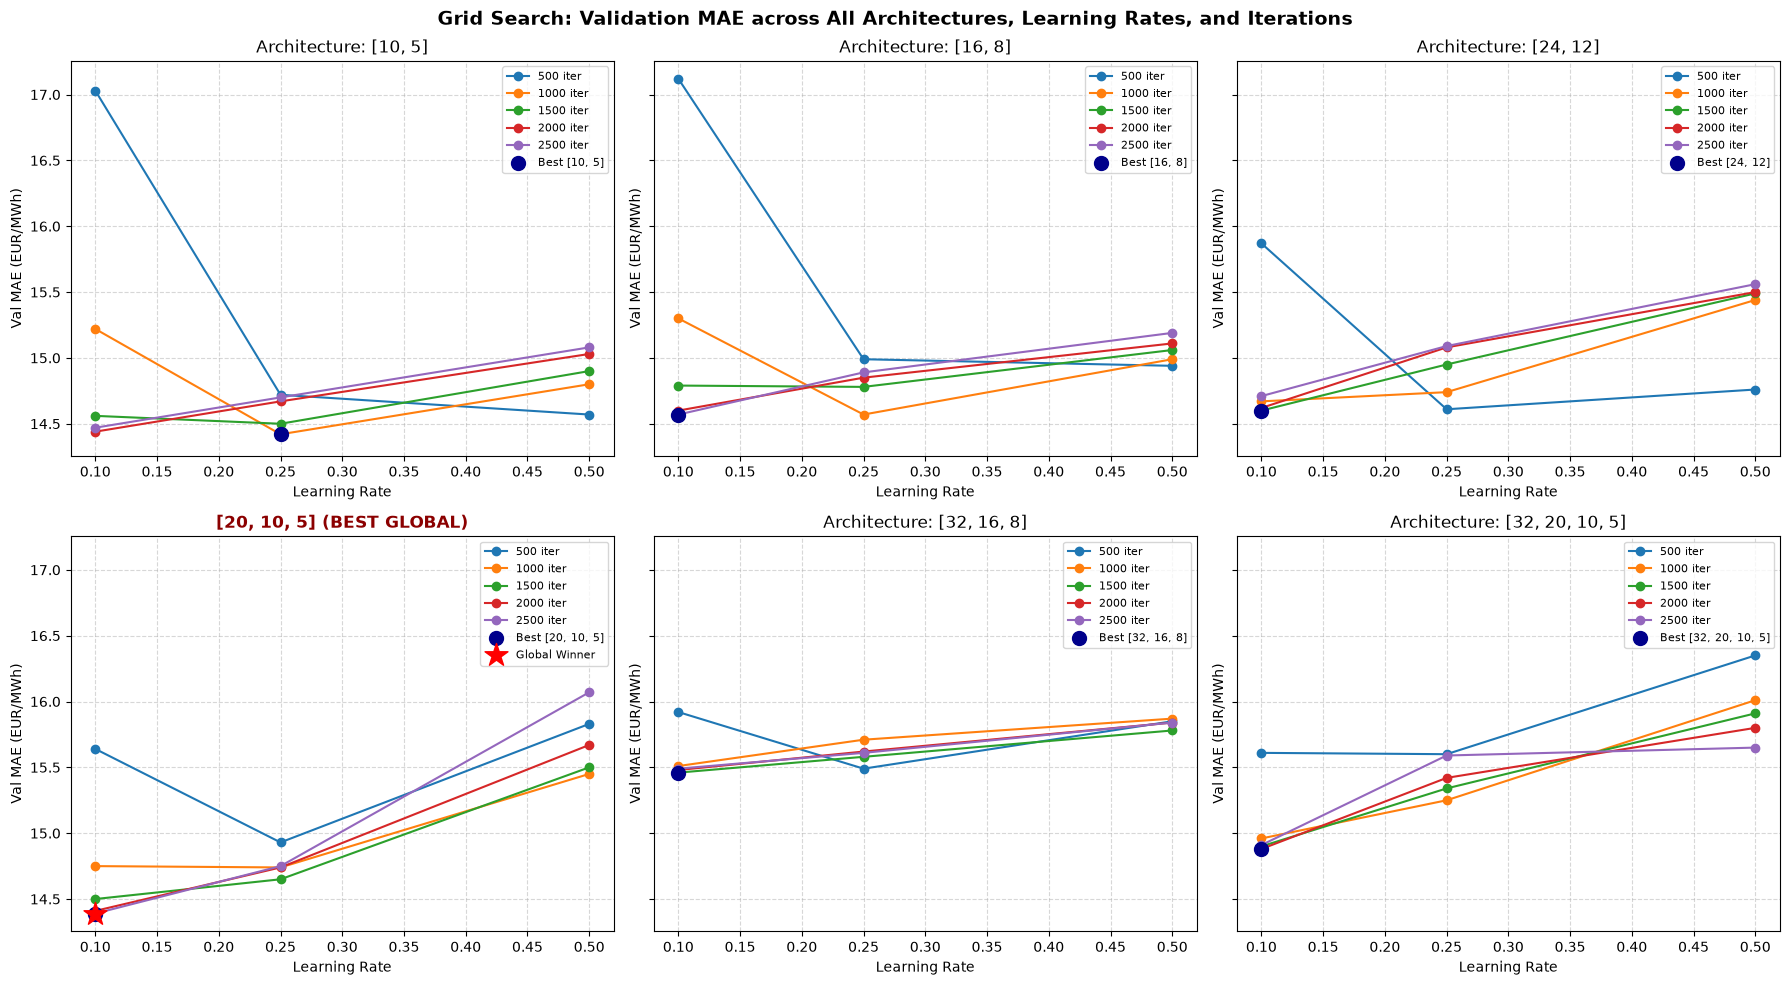

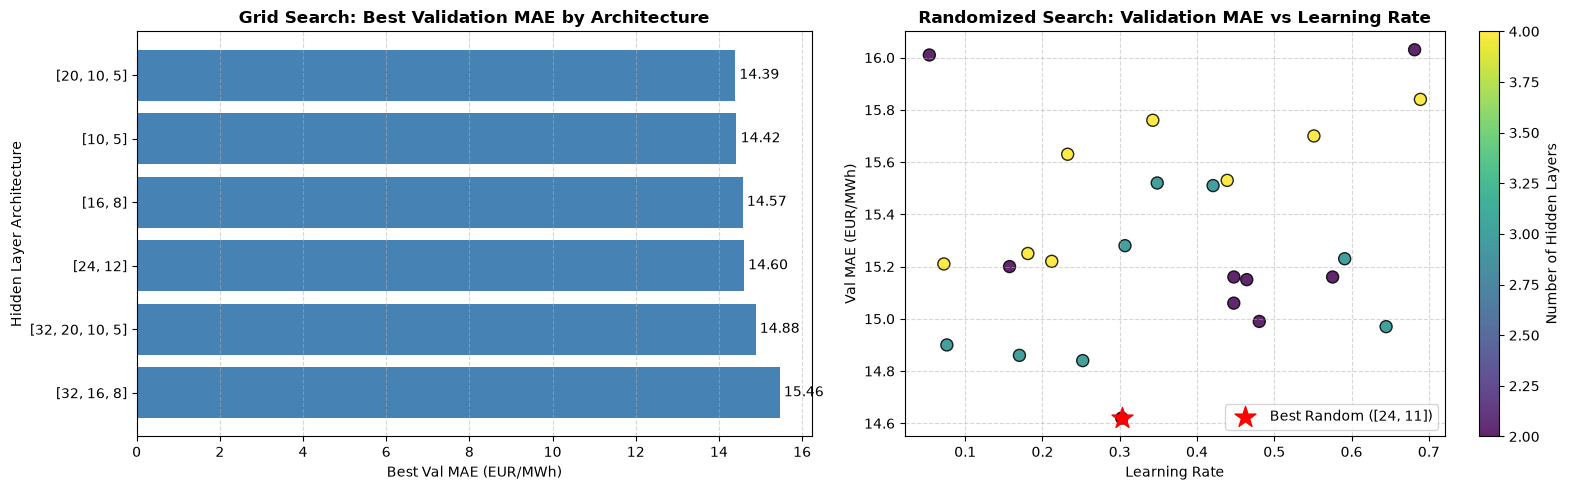

In [25]:
# 1. Grid Search: A dedicated subplot for each of the 6 architectures
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharey=True)
axes = axes.flatten()

arch_names = list(architectures.keys())
best_arch_global = best_row["Hidden_Layers"]
best_lr_global = best_row["Learning_Rate"]
best_mae_global = best_row["Val_MAE (EUR/MWh)"]

for idx, arch_name in enumerate(arch_names):
    ax = axes[idx]
    df_arch = df_grid[df_grid["Hidden_Layers"] == arch_name]
    
    for n_iter in iterations_list:
        subset = df_arch[df_arch["Iterations"] == n_iter]
        ax.plot(subset["Learning_Rate"], subset["Val_MAE (EUR/MWh)"], marker="o", label=f"{n_iter} iter")
    
    # Best configuration in this specific architecture
    best_in_arch = df_arch.loc[df_arch["Val_MAE (EUR/MWh)"].idxmin()]
    ax.scatter(best_in_arch["Learning_Rate"], best_in_arch["Val_MAE (EUR/MWh)"], color="darkblue", s=100, zorder=4, label=f"Best {arch_name}")
    
    # Global winner marked with red star
    if arch_name == best_arch_global:
        ax.scatter(best_lr_global, best_mae_global, color="red", marker="*", s=300, zorder=6, label="Global Winner")
        ax.set_title(f"{arch_name} (BEST GLOBAL)", fontweight="bold", color="darkred")
    else:
        ax.set_title(f"Architecture: {arch_name}")
        
    ax.set_xlabel("Learning Rate")
    ax.set_ylabel("Val MAE (EUR/MWh)")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(fontsize=8)

plt.suptitle("Grid Search: Validation MAE across All Architectures, Learning Rates, and Iterations", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# 2. Architecture Comparison Bar Chart & Randomized Search Analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Subplot A: Best MAE achieved by each Grid Search architecture
best_per_arch = df_grid.groupby("Hidden_Layers")["Val_MAE (EUR/MWh)"].min().reset_index()
best_per_arch = best_per_arch.sort_values(by="Val_MAE (EUR/MWh)", ascending=True)

bars = axes[0].barh(best_per_arch["Hidden_Layers"], best_per_arch["Val_MAE (EUR/MWh)"], color="steelblue")
axes[0].invert_yaxis()
axes[0].set_title("Grid Search: Best Validation MAE by Architecture", fontweight="bold")
axes[0].set_xlabel("Best Val MAE (EUR/MWh)")
axes[0].set_ylabel("Hidden Layer Architecture")
axes[0].grid(True, linestyle="--", alpha=0.5, axis="x")
axes[0].bar_label(bars, fmt="%.2f", padding=3)

# Subplot B: Randomized Search - Val MAE vs Learning Rate colored by Number of Hidden Layers
scatter = axes[1].scatter(
    df_random["Learning_Rate"], 
    df_random["Val_MAE (EUR/MWh)"], 
    c=df_random["Num_Layers"], 
    cmap="viridis", 
    s=75, 
    alpha=0.85, 
    edgecolor="k"
)
cbar = plt.colorbar(scatter, ax=axes[1])
cbar.set_label("Number of Hidden Layers")
axes[1].scatter(
    best_random_row["Learning_Rate"], 
    best_random_row["Val_MAE (EUR/MWh)"], 
    color="red", 
    marker="*", 
    s=250, 
    zorder=5, 
    label=f"Best Random ({best_random_row['Hidden_Layers']})"
)
axes[1].set_title("Randomized Search: Validation MAE vs Learning Rate", fontweight="bold")
axes[1].set_xlabel("Learning Rate")
axes[1].set_ylabel("Val MAE (EUR/MWh)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 5.3 - Evaluation on the Final Test Set 
Using the optimal hyperparameters found in validation, we evaluate our 12-feature DNN on the 2nd half of 2025 and plot the 1-week forecast.

In [26]:
best_arch_str = best_row["Hidden_Layers"]
best_dims_12  = architectures[best_arch_str]
best_lr       = float(best_row["Learning_Rate"])
best_iter     = int(best_row["Iterations"])

params_best_12, costs_best_12 = L_layer_model(
    train_set_x_normalized, train_set_y_normalized,
    layers_dims=best_dims_12, learning_rate=best_lr, num_iterations=best_iter, print_cost=False
)

Y_pred_test_final = predict(params_best_12, X_test_final_norm)
test_final_acc = 100 - np.mean(np.abs(Y_pred_test_final - Y_test_final_norm)) * 100

y_pred_test_final_eur = scaler.inverse_transform(Y_pred_test_final.T)
test_final_mae  = np.mean(np.abs(y_pred_test_final_eur - y_test_final_orig))
test_final_rmse = np.sqrt(np.mean((y_pred_test_final_eur - y_test_final_orig) ** 2))

print(f"Hyperparameters used -> Hidden Layers: {best_arch_str} | Learning Rate: {best_lr} | Iterations: {best_iter}")
print(f"Final Test Accuracy: {test_final_acc:.2f} %")
print(f"Final Test MAE:      {test_final_mae:.2f} EUR/MWh")
print(f"Final Test RMSE:     {test_final_rmse:.2f} EUR/MWh")

Hyperparameters used -> Hidden Layers: [20, 10, 5] | Learning Rate: 0.1 | Iterations: 2500
Final Test Accuracy: 94.23 %
Final Test MAE:      14.71 EUR/MWh
Final Test RMSE:     18.88 EUR/MWh


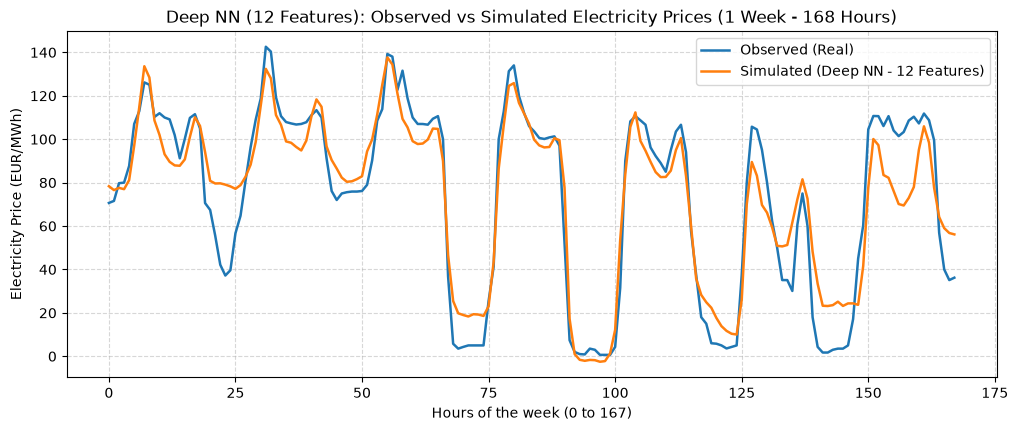

In [27]:
# Observed vs Simulated for 1 Week (168 hours) on the Final Test Set
hours_week = np.arange(0, 168, 1)
y_obs_week  = y_test_final_orig[:168]
y_pred_week = y_pred_test_final_eur[:168]

plt.figure(figsize=(12, 4.5))
plt.plot(hours_week, y_obs_week, label="Observed (Real)", linewidth=1.8)
plt.plot(hours_week, y_pred_week, label="Simulated (Deep NN - 12 Features)", linewidth=1.8)
plt.title("Deep NN (12 Features): Observed vs Simulated Electricity Prices (1 Week - 168 Hours)")
plt.xlabel("Hours of the week (0 to 167)")
plt.ylabel("Electricity Price (EUR/MWh)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# 6 - Feature importance study & reduced model 
## 6.1 - Feature importance 
As in the Shallow Neural Network, we measure the importance of each normalized input feature by calculating the mean absolute weight connecting that input to all neurons in the first hidden layer.

              Feature  Mean_Abs_W1
      Wind_Onshore_MW     0.301030
           Price_t_24     0.295973
     Load_Forecast_MW     0.256303
             Solar_MW     0.247107
          Price_t_168     0.241892
                Month     0.236821
                 Hour     0.225292
         Price_24h_MA     0.218810
  Hydro_Reservoir_MWh     0.216816
Nuclear_Generation_MW     0.214748
           Is_Weekend     0.200801
           Price_t_48     0.186644


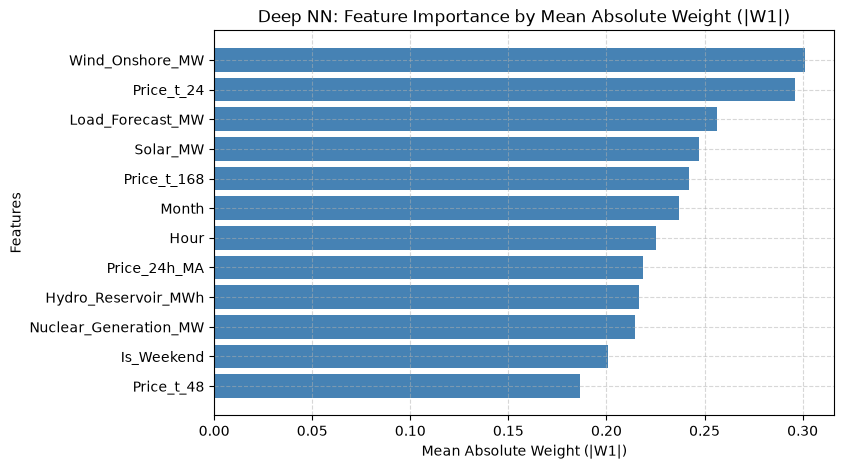

In [28]:
feature_names = df.columns[2:].tolist()

# Compute mean absolute weight across first-layer hidden units for each input feature
mean_abs_w1 = np.mean(np.abs(params_best_12["W1"]), axis=0)

importance_dnn_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Abs_W1": mean_abs_w1
}).sort_values(by="Mean_Abs_W1", ascending=False)

print(importance_dnn_df.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.barh(importance_dnn_df["Feature"], importance_dnn_df["Mean_Abs_W1"], color="steelblue")
plt.gca().invert_yaxis()
plt.title("Deep NN: Feature Importance by Mean Absolute Weight (|W1|)")
plt.xlabel("Mean Absolute Weight (|W1|)")
plt.ylabel("Features")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 6.2 - Retraining the DNN with 9 features
From the DNN feature importance ranking above, the 3 features with the lowest weights are:
- Hydro_Reservoir_MWh (0.184)
- Price_t_48 (0.184)
- Hour (0.18)

We remove these 3 lowest-impact variables (indices [1, 6, 9]), keeping the top 9 features (keep_indices = [0, 2, 3, 4, 5, 7, 8, 10, 11]), and retrain the Deep Neural Network using the optimal hyperparameters (layers_dims = [9, 10, 5, 1]).

In [29]:
# Keep the top 9 features (removing Hydro_Reservoir_MWh [1], Price_t_48 [6], Hour [9])
keep_indices = [0, 2, 3, 4, 5, 7, 8, 10, 11]

train_set_x_reduced = train_set_x_normalized[keep_indices, :]
test_set_x_reduced  = test_set_x_normalized[keep_indices, :]

best_dims_9 = [9] + best_dims_12[1:]

parameters_reduced, costs_reduced = L_layer_model(
    train_set_x_reduced,
    train_set_y_normalized,
    layers_dims=best_dims_9,
    learning_rate=best_lr,
    num_iterations=best_iter,
    print_cost=True
)

Y_prediction_train_red = predict(parameters_reduced, train_set_x_reduced)
Train_accuracy_red = 100 - np.mean(np.abs(Y_prediction_train_red - train_set_y_normalized)) * 100

Y_prediction_test_red = predict(parameters_reduced, test_set_x_reduced)
Test_accuracy_red = 100 - np.mean(np.abs(Y_prediction_test_red - test_set_y_normalized)) * 100

print("Reduced Model (9 Features) - Train Accuracy: {} %".format(Train_accuracy_red))
print("Reduced Model (9 Features) - Test Accuracy:  {} %".format(Test_accuracy_red))

Cost after iteration 0: 0.716943
Cost after iteration 100: 0.638350
Cost after iteration 200: 0.619374
Cost after iteration 300: 0.597399
Cost after iteration 400: 0.582929
Cost after iteration 500: 0.575685
Cost after iteration 600: 0.571753
Cost after iteration 700: 0.569321
Cost after iteration 800: 0.567708
Cost after iteration 900: 0.566545
Cost after iteration 1000: 0.565655
Cost after iteration 1100: 0.564939
Cost after iteration 1200: 0.564328
Cost after iteration 1300: 0.563780
Cost after iteration 1400: 0.563275
Cost after iteration 1500: 0.562838
Cost after iteration 1600: 0.562460
Cost after iteration 1700: 0.562128
Cost after iteration 1800: 0.561825
Cost after iteration 1900: 0.561548
Cost after iteration 2000: 0.561289
Cost after iteration 2100: 0.561044
Cost after iteration 2200: 0.560813
Cost after iteration 2300: 0.560593
Cost after iteration 2400: 0.560383
Reduced Model (9 Features) - Train Accuracy: 93.36942212724739 %
Reduced Model (9 Features) - Test Accuracy:  93

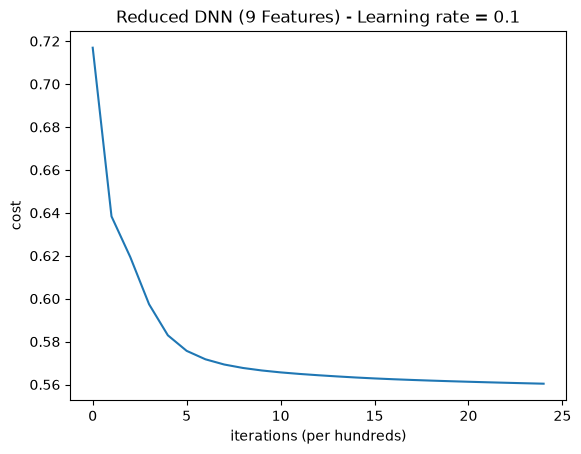

In [30]:
# Cost curve for the Reduced DNN Model (9 Features)
plt.plot(np.squeeze(costs_reduced))
plt.ylabel("cost")
plt.xlabel("iterations (per hundreds)")
plt.title("Reduced DNN (9 Features) - Learning rate = " + str(best_lr))
plt.show()

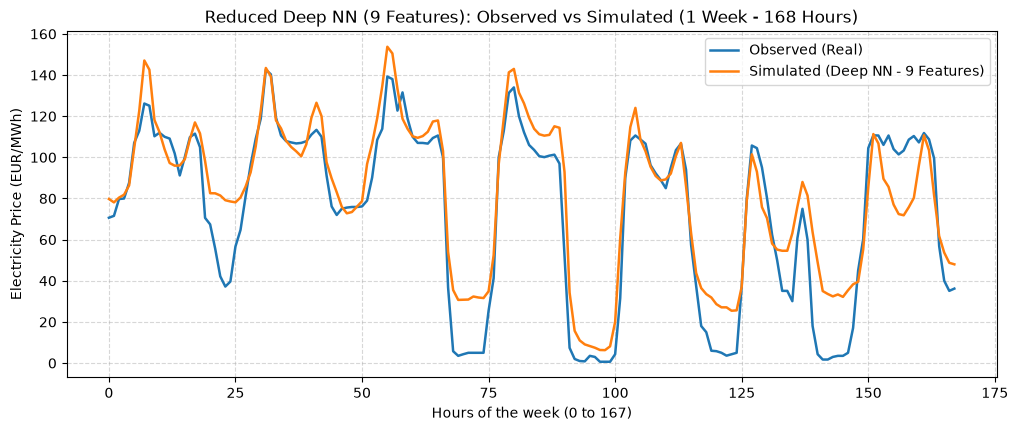

In [31]:
# Reverse normalization and plot 1-week Observed vs Simulated for Reduced DNN (9 Features)
X_test_final_reduced = X_test_final_norm[keep_indices, :]
Y_pred_test_final_red = predict(parameters_reduced, X_test_final_reduced)
test_final_red_acc = 100 - np.mean(np.abs(Y_pred_test_final_red - Y_test_final_norm)) * 100

y_pred_test_final_red_eur = scaler.inverse_transform(Y_pred_test_final_red.T)
test_final_red_mae  = np.mean(np.abs(y_pred_test_final_red_eur - y_test_final_orig))
test_final_red_rmse = np.sqrt(np.mean((y_pred_test_final_red_eur - y_test_final_orig) ** 2))

hours_week = np.arange(0, 168, 1)
plt.figure(figsize=(12, 4.5))
plt.plot(hours_week, y_test_final_orig[:168], label="Observed (Real)", linewidth=1.8)
plt.plot(hours_week, y_pred_test_final_red_eur[:168], label="Simulated (Deep NN - 9 Features)", linewidth=1.8)
plt.title("Reduced Deep NN (9 Features): Observed vs Simulated (1 Week - 168 Hours)")
plt.xlabel("Hours of the week (0 to 167)")
plt.ylabel("Electricity Price (EUR/MWh)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 6.3 - Final Comparison: Full DNN (12 Features) vs. Reduced DNN (9 Features)

In [32]:
comparison_dnn_df = pd.DataFrame([
    {
        "Model": "Deep NN - Full (12 Features)",
        "Hidden_Layers": best_arch_str,
        "Learning_Rate": best_lr,
        "Iterations": best_iter,
        "Final_Test_Acc (%)": round(test_final_acc, 2),
        "Final_Test_MAE (EUR/MWh)": round(test_final_mae, 2),
        "Final_Test_RMSE (EUR/MWh)": round(test_final_rmse, 2)
    },
    {
        "Model": "Deep NN - Reduced (9 Features)",
        "Hidden_Layers": best_arch_str,
        "Learning_Rate": best_lr,
        "Iterations": best_iter,
        "Final_Test_Acc (%)": round(test_final_red_acc, 2),
        "Final_Test_MAE (EUR/MWh)": round(test_final_red_mae, 2),
        "Final_Test_RMSE (EUR/MWh)": round(test_final_red_rmse, 2)
    }
])

print(comparison_dnn_df.to_string(index=False))

                         Model Hidden_Layers  Learning_Rate  Iterations  Final_Test_Acc (%)  Final_Test_MAE (EUR/MWh)  Final_Test_RMSE (EUR/MWh)
  Deep NN - Full (12 Features)   [20, 10, 5]            0.1        2500               94.23                     14.71                      18.88
Deep NN - Reduced (9 Features)   [20, 10, 5]            0.1        2500               94.20                     14.79                      18.75
